### Вариант 5. Проблема исчезновения градиента

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
%matplotlib inline
import warnings

warnings.filterwarnings( "ignore")

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
!pip3 install torch torchvision

In [ ]:
data = fetch_california_housing()
X, y = data.data, data.target

X_train, X_holdout, y_train, y_holdout = train_test_split(X, y, test_size=0.3, random_state=17)
X_holdout, X_val, y_holdout, y_val = train_test_split(X_holdout, y_holdout, test_size=0.5,  random_state=17)

In [ ]:
import torch
from torch import nn

def X_to_tensor(X):
    X_tensor = torch.tensor(StandardScaler().fit(X_train).transform(X))
    return X_tensor

def y_to_tensor(y):
    y_tensor = torch.tensor(StandardScaler().fit(y_train.reshape(-1, 1)).transform(y.reshape(-1, 1)))
    return y_tensor

X_tr = X_to_tensor(X_train).float()
X_h = X_to_tensor(X_holdout).float()
X_v = X_to_tensor(X_val).float()

y_tr = y_to_tensor(y_train).float()
y_h = y_to_tensor(y_holdout).float()
y_v = y_to_tensor(y_val).float()

n = 64

In [ ]:
class Model(nn.Module):
  def __init__(self, depth, activation):
    super().__init__()
    self.layers = nn.ModuleList()
    self.layers.append(nn.Linear(X_tr.shape[1], n))
    for i in range (depth - 1):
      self.layers.append(nn.Linear(n, n))
    self.layers.append(nn.Linear(n, 1))
    self.activation = {"sigmoid": torch.sigmoid,
                       "tanh": torch.tanh,
                       "relu": torch.relu}[activation]

  def forward(self, x):
    for layer in self.layers[:-1]:
      x = self.activation(layer(x))
    last_layer = self.layers[-1](x)
    return last_layer

In [71]:
def init_weights(model, name, std=None):
  for i in model.layers:
    if name == "xavier":
      nn.init.xavier_normal_(i.weight)
    elif name == "he":
      nn.init.kaiming_normal_(i.weight, nonlinearity="relu")
    elif name == "default":
      nn.init.normal_(i.weight, 0.0, 1/np.sqrt(i.in_features))
    elif name == "big":
      nn.init.normal_(i.weight, 0.0, std)
    nn.init.zeros_(i.bias)


In [ ]:
criterion = nn.MSELoss()
X_fix, y_fix = X_tr[:1000], y_tr[:1000]

def grad_norm(model):
  model.zero_grad()
  criterion(model(X_fix), y_fix).backward()
  return np.array([i.weight.grad.norm().item() for i in model.layers])


In [87]:
def train_model(depth, activation, init, std=None, lr = 0.01, epochs=10, batch=128, seed=2):
  torch.manual_seed(seed)
  model = Model(depth, activation)
  init_weights(model, init, std)
  optimizer = torch.optim.SGD(model.parameters(), lr=lr)
  loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch, shuffle=True)
  result = {"start": grad_norm(model), "end": None, "epoch_loss": [], "it_loss": [], "it_norm": [], "test_loss": None, "nan_iter": None}

  for e in range(epochs):
    for x, y in loader:
      optimizer.zero_grad()
      loss = criterion(model(x), y)
      if not torch.isfinite(loss):
        result["nan_iter"] = len(result["it_loss"])
        return result
      loss.backward()
      total = sum(p.grad.norm()**2 for p in model.parameters())**0.5
      result["it_norm"].append(total.item())
      result["it_loss"].append(loss.item())
      optimizer.step()
    result["epoch_loss"].append(np.mean(result["it_loss"][-len(loader):]))

  result["end"] = grad_norm(model)

  with torch.no_grad():
    result["test_loss"] = criterion(model(X_h), y_h).item()
  return result


def norm_change(norms):
  t, _ = np.polyfit(np.arange(len(norms)), np.log(norms), 1)
  return np.exp(-t)




### Задание 2

Для каждой глубины постройте гистограмму норм градиентов по слоям на первой эпохе и после 10 эпох. Покажите экспоненциальное затухание.

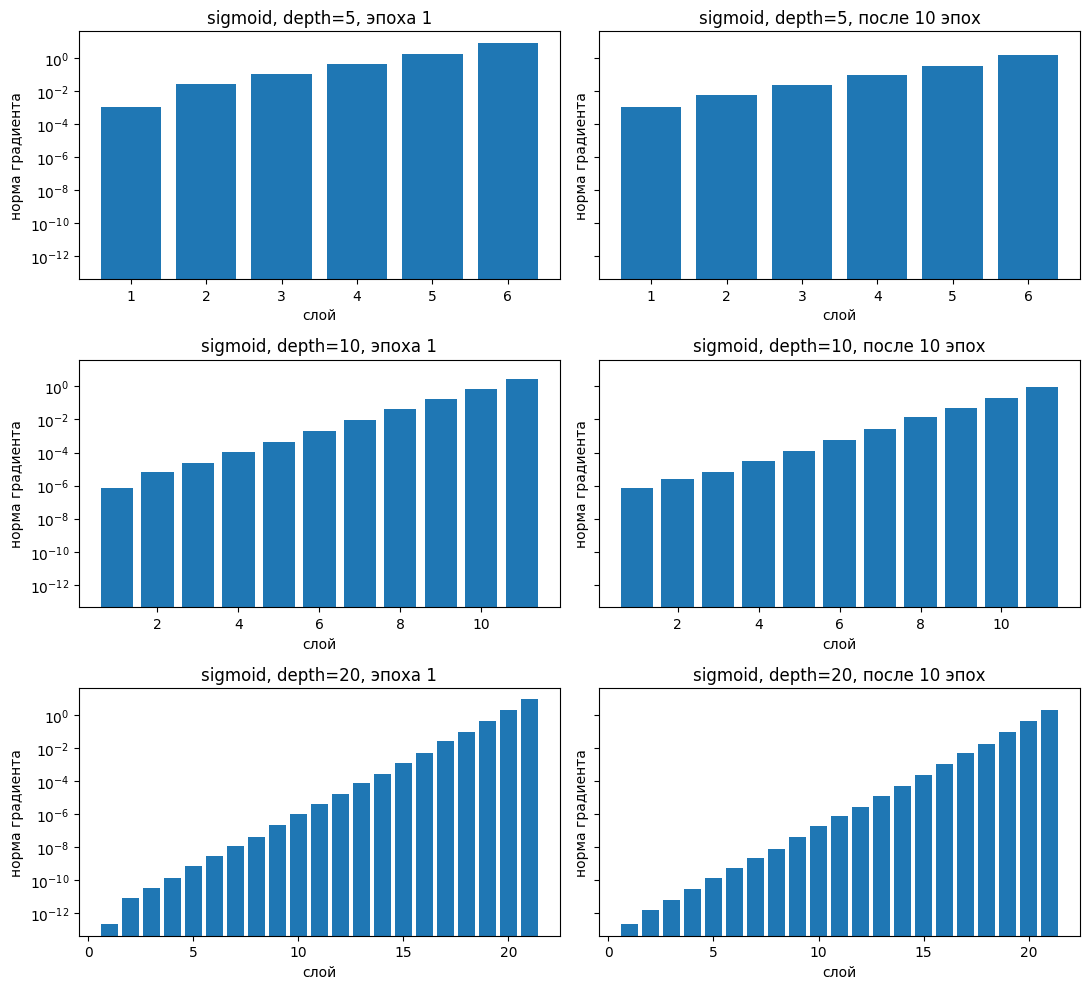

 depth  q (эпоха 1)  q (после 10)  train loss  test loss
     5     0.189443      0.246143    1.005468   0.990220
    10     0.224875      0.236835    1.005364   0.983750
    20     0.227363      0.231048    1.005172   1.005045


In [85]:
DEPTH = [5, 10, 20]

att = {d: train_model(d, "sigmoid", "default") for d in DEPTH}

fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharey=True)
for i, dp in enumerate(DEPTH):
  for j, (key, title) in enumerate([("start", "эпоха 1"), ("end", "после 10 эпох")]):
    norms = att[dp][key]
    axes[i, j].bar(np.arange(1, len(norms)+1), norms)
    axes[i, j].set_yscale("log")
    axes[i, j].set_title(f'sigmoid, depth={dp}, {title}')
    axes[i, j].set_xlabel('слой')
    axes[i, j].set_ylabel('норма градиента')
plt.tight_layout()
plt.show()

rows = []
for dp in DEPTH:
    s, e = att[dp]["start"], att[dp]["end"]
    rows.append({"depth": dp,
                 "q (эпоха 1)": norm_change(s), "q (после 10)": norm_change(e),
                 "train loss": att[dp]["epoch_loss"][-1],
                 "test loss": att[dp]["test_loss"]})
print(pd.DataFrame(rows).to_string(index=False))



Данные гистограммы норм градиентов по слоям показывают экспоненциальное затухание. Значение q показывает, во сколько раз менятеся норма при движении ко входу сети на каждом шаге. Значение q < 1 на всех графиках, то есть градиенты затухают. Приэтом заметим, что q немного выросле после 10 эпохи, но все еще меньше 0.25.




---
### Задание 4

Повторите эксперимент с tanh и с инициализацией Xavier/He. Насколько меняется картина?


активация инициализация  depth  q на слой  1-ый/последний  train_loss  test_loss
  sigmoid       default      5   0.189443    1.441528e-04    1.001970   0.983012
  sigmoid       default     10   0.224875    2.556402e-07    1.001696   0.983352
  sigmoid       default     20   0.227363    2.666092e-14    1.001177   0.984134
  sigmoid        xavier      5   0.195271    1.773636e-04    1.002129   0.983126
  sigmoid        xavier     10   0.225213    2.707774e-07    1.001819   0.983316
  sigmoid        xavier     20   0.227571    2.872161e-14    1.001252   0.984399
  sigmoid            he      5   0.239295    4.092400e-04    0.997567   0.978279
  sigmoid            he     10   0.297009    3.495502e-06    1.001914   0.983291
  sigmoid            he     20   0.301393    5.735489e-12    1.001285   0.984520
     tanh       default      5   0.915969    4.157914e-01    0.305035   0.306518
     tanh       default     10   0.968747    4.823625e-01    0.270560   0.259744
     tanh       default     

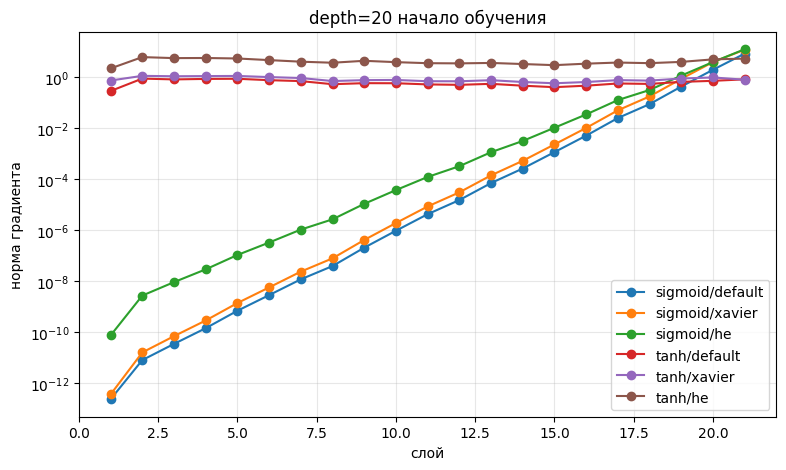

In [88]:
rows, res = [], {}
for a in ["sigmoid", "tanh"]:
  for i in ['default', 'xavier', 'he']:
    for dp in DEPTH:
      r = train_model(dp, a, i)
      res[(a, i, dp)] = r
      g = r["start"]
      rows.append({"активация": a, 'инициализация': i, "depth": dp,
                   "q на слой": norm_change(g), "1-ый/последний": g[0]/g[-1],
                   "train_loss": r["epoch_loss"][-1] if r["epoch_loss"] else np.nan,
                   "test_loss": r["test_loss"]})
print(pd.DataFrame(rows).to_string(index=False))

plt.figure(figsize=(9, 5))
for (a, i, dp), r in res.items():
    if dp == 20:
        plt.plot(np.arange(1, len(r['start'])+1), r['start'],
                 marker='o', label=f'{a}/{i}')
plt.yscale('log')
plt.xlabel('слой')
plt.ylabel('норма градиента')
plt.title('depth=20 начало обучения')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Сразу можно заметить отличие графиков с сигмоидой и тангенсом - при использоавнии тангенса графики находятся в райное прямой y=1, то есть градиент не меняется на протяжении всех слоев (вне зависимости от инициализации he/xavier). А графики с сигмоидой опускаются при проходе с последнего слоя к началу, то есть градиент постепенно затухает и норма опускается примерно до 10^(-12), также вне зависимости от способа инициализации. Можно только заметить, что He немного улучшает ситуацию по сравнению с Xavier и типичной инициализацией - значение q = 0.30 на 20 эпохах при использовании сигмоиды, а остальные инициализации дают только q = ~0.22.



---

### Задание 5
Исследуйте взрыв градиента: инициализируйте веса большими значениями, покажите рост нормы градиента и NaN в лоссе.

big, std=0.5: NaN/inf на итерации 1
big, std=1.0: NaN/inf на итерации 1
he, std=None: NaN нет


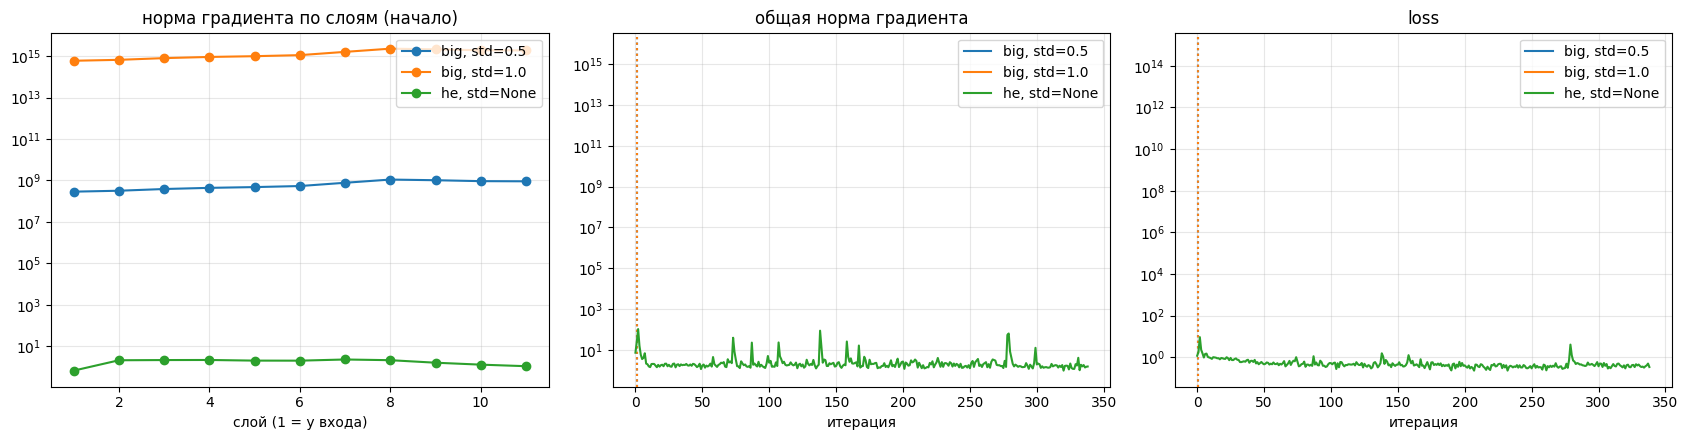

std=0.5: q теор = 2.83, q эксп = 0.87
std=1.0: q теор = 5.66, q эксп = 0.87


In [74]:
expl = {}
for i, std in [('big', 0.5), ('big', 1.0), ('he', None)]:
    expl[(i, std)] = train_model(10, 'relu', i, std=std, epochs=3, lr=0.01)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for (i, std), r in expl.items():
    label = f'{i}, std={std}'
    axes[0].plot(np.arange(1, len(r['start'])+1), r['start'], marker='o', label=label)
    line, = axes[1].plot(r['it_norm'], label=label)
    axes[2].plot(r['it_loss'], label=label)
    if r['nan_iter'] is not None:
        print(f'{label}: NaN/inf на итерации {r["nan_iter"]}')
        axes[1].axvline(r['nan_iter'], color=line.get_color(), ls=':')
        axes[2].axvline(r['nan_iter'], color=line.get_color(), ls=':')
    else:
        print(f'{label}: NaN нет')

axes[0].set_title('норма градиента по слоям (начало)'); axes[0].set_xlabel('слой (1 = у входа)')
axes[1].set_title('общая норма градиента');             axes[1].set_xlabel('итерация')
axes[2].set_title('loss');                              axes[2].set_xlabel('итерация')
for ax in axes:
    ax.set_yscale('log'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for std in [0.5, 1.0]:
    print(f'std={std}: q теор = {std * np.sqrt(n / 2):.2f}, '
          f'q эксп = {norm_change(expl[("big", std)]["start"]):.2f}')

В данном случае мы испотзуем функциб ReLU, так как у нее градиент не затухает при больших весах, а наоборот (производная равна единице на положительной оси).  При инициализации весов большими значениями видно, что значение градиента сразу огромно (на левом графики показаны градиенты на каждом слое при инициализации). На втором графике можно заметить взрыв градиента (оранжевый и синий графики), после первой итерации loss устремился к бесконечности. Норма градиента по итерациям зеленой линии колеблется примерно на одном уровне - около 10. Также знаечние loss можно увидеть на правом графике - зеленая линия медленно идет вниз, а другие графики, инициализированные большими значениями сразу принимают inf.


### Выводы

Затухание может лечить ReLU, так как производная всегда будет равняться 1 у положительных чисел и не будет давать градиенту уменьшаться. Для инициализации лучше использовать He, хоть она показала и незначительные улучшения.
 Глубина является важным фактором при затухании градиента, так как при движении в началу сети накапливается произведения, то есть показатель степени к первому слою будет в разы больше, тем самым градиент будет очень маленьким.